# Lineup Protocol (visual inference)

**Family:** Scientific &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Scientific:* Domain-neutral statistics and research plots: effect sizes, meta-analysis, agreement, omics, replicates and visual inference.

## Design purpose

Hides the real chart among 19 "null" charts generated from data where the pattern cannot exist, for example by shuffling the order of returns. If an honest viewer can pick out the real chart, the pattern is unlikely to be chance (p ≈ 1/20 = 0.05 for one viewer). The chart becomes a statistical test, with human perception as the test statistic.

## When to use

- Check whether a pattern you see (a trend, momentum, clustering, a spatial hot spot) is real or a trick of the eye
- Test a pattern for which no convenient formal test exists
- Teach analysts how easily randomness produces convincing-looking patterns

## Avoid when

- A standard formal test answers the question directly and the audience trusts it
- The viewer has already seen the real chart (they will recognise it, which invalidates the test)
- Final presentation of a result (show the finding itself; keep the lineup in the appendix or the analysis)

## Alternatives

- Rorschach plots (all nulls, to calibrate your eye)
- A permutation test reported as a number

## Design tips

- What it fixes: our eyes find patterns in noise; the lineup gives an exploratory chart a p-value
- Generate nulls that destroy only the pattern you are testing (shuffling returns destroys time dependence but keeps the return distribution)
- Draw every panel identically (same color, same scales policy) and number them; never highlight the real one
- With k independent viewers who each pick the real panel, p ≈ (1/20)^k
- R implementation by the method's authors: the `nullabor` package

## Example

A simulated weekly price series with momentum (positive autocorrelation in returns) placed at a random position among 19 series built by shuffling its own weekly returns. The real-data variant does the same with Apple's weekly returns, 2018–2019.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(2010)
n = 156  # three years of weekly returns
eps = rng.normal(0, 0.02, n)
real = np.empty(n)
real[0] = eps[0]
for t in range(1, n):  # momentum: this week's return carries over into the next
    real[t] = 0.6 * real[t - 1] + eps[t]
real += 0.001
answer = 15  # position of the real series (keep it secret from your viewers)


def lineup(real_returns, answer, n_panels=20, seed=0):
    """Price paths: the real one at `answer`, the rest from shuffled copies of its returns."""
    g = np.random.default_rng(seed)
    paths = [g.permutation(real_returns) for _ in range(n_panels)]
    paths[answer - 1] = real_returns
    return [100 * np.cumprod(1 + r) for r in paths]


panels = lineup(real, answer)
title = "Which price path is real? The other 19 are shuffled copies of its weekly returns (simulated)"
f"lag-1 autocorrelation of the real returns: {np.corrcoef(real[:-1], real[1:])[0, 1]:.2f}"

'lag-1 autocorrelation of the real returns: 0.49'

### Plot

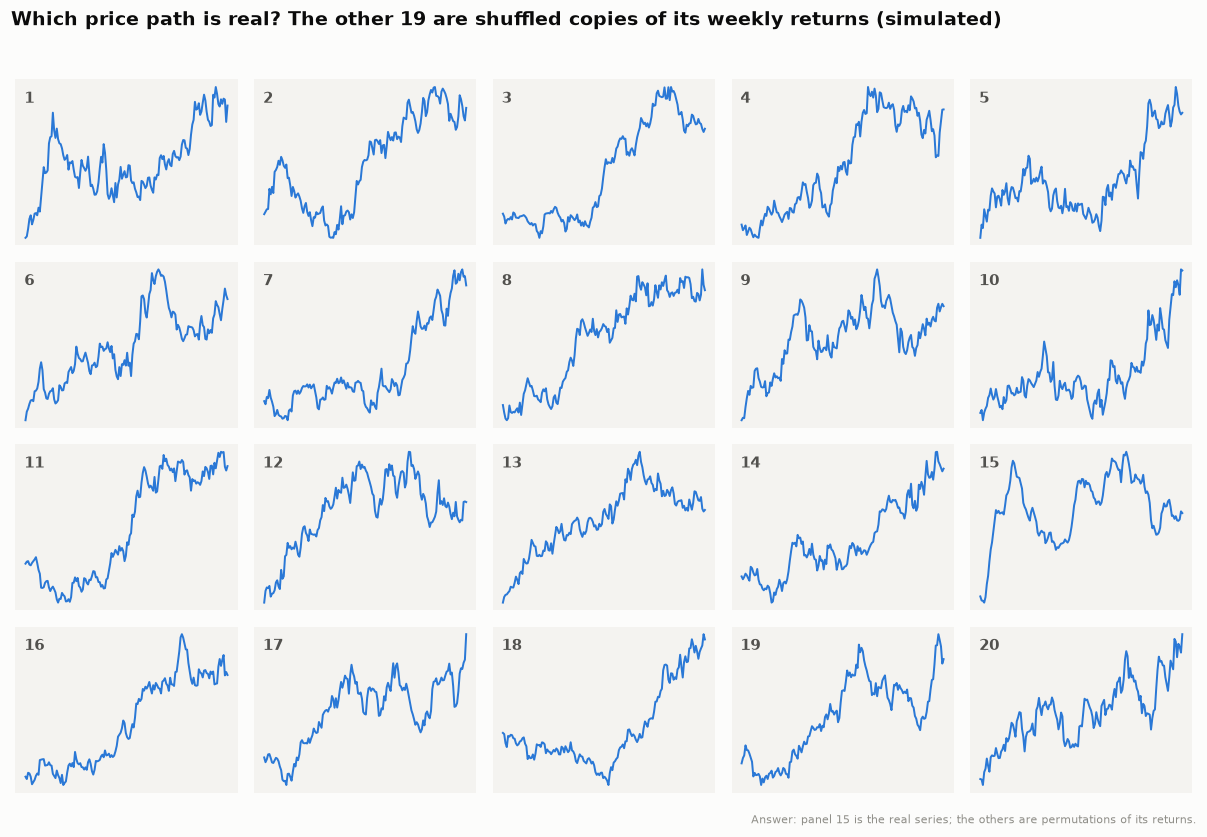

In [3]:
fig, axes = plt.subplots(4, 5, figsize=(11, 7.6))
for k, (ax, path) in enumerate(zip(axes.flat, panels), start=1):
    ax.plot(path, color=PALETTE[0], linewidth=1.3)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.set_facecolor("#f4f3f0")
    for s in ax.spines.values():
        s.set_visible(False)
    ax.text(0.04, 0.86, str(k), transform=ax.transAxes, fontsize=10, color="#52514e", fontweight="bold")
fig.suptitle(title, x=0.01, ha="left", fontweight="bold", fontsize=12.5)
fig.text(0.99, 0.008, f"Answer: panel {answer} is the real series; the others are permutations of its returns.",
         ha="right", fontsize=7.5, color="#8f8e88")
fig.tight_layout(rect=(0, 0.025, 1, 0.96))
plt.show()

## How to read it

Look for the panel whose path is smoother and trendier than the rest. That is momentum, which shuffling destroys. The answer is printed in small type below the figure (panel 15 for the simulated data). With the real AAPL returns, most viewers cannot pick the real panel, which is itself the finding: there is no visible evidence of momentum in those two years of weekly returns.

## Reference

This method comes from the research literature:

- Buja, A., Cook, D., Hofmann, H., Lawrence, M., Lee, E.-K., Swayne, D. F. & Wickham, H. (2009). Statistical inference for exploratory data analysis and model diagnostics. Philosophical Transactions of the Royal Society A 367, 4361–4383. <https://doi.org/10.1098/rsta.2009.0120>
- Wickham, H., Cook, D., Hofmann, H. & Buja, A. (2010). Graphical inference for infovis. IEEE Transactions on Visualization and Computer Graphics 16(6), 973–979. <https://vita.had.co.nz/papers/inference-infovis.html>

## Try it with real data

**Source:** plotly.express.data.stocks (AAPL weekly returns, 2018–2019)

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
import plotly.express as px

real = px.data.stocks()["AAPL"].pct_change().dropna().to_numpy()
answer = 7
panels = lineup(real, answer)
title = "Which is Apple's real weekly price path (2018–2019)? The other 19 are shuffled copies of its returns"
f"lag-1 autocorrelation of AAPL weekly returns: {np.corrcoef(real[:-1], real[1:])[0, 1]:.2f}"

'lag-1 autocorrelation of AAPL weekly returns: 0.04'

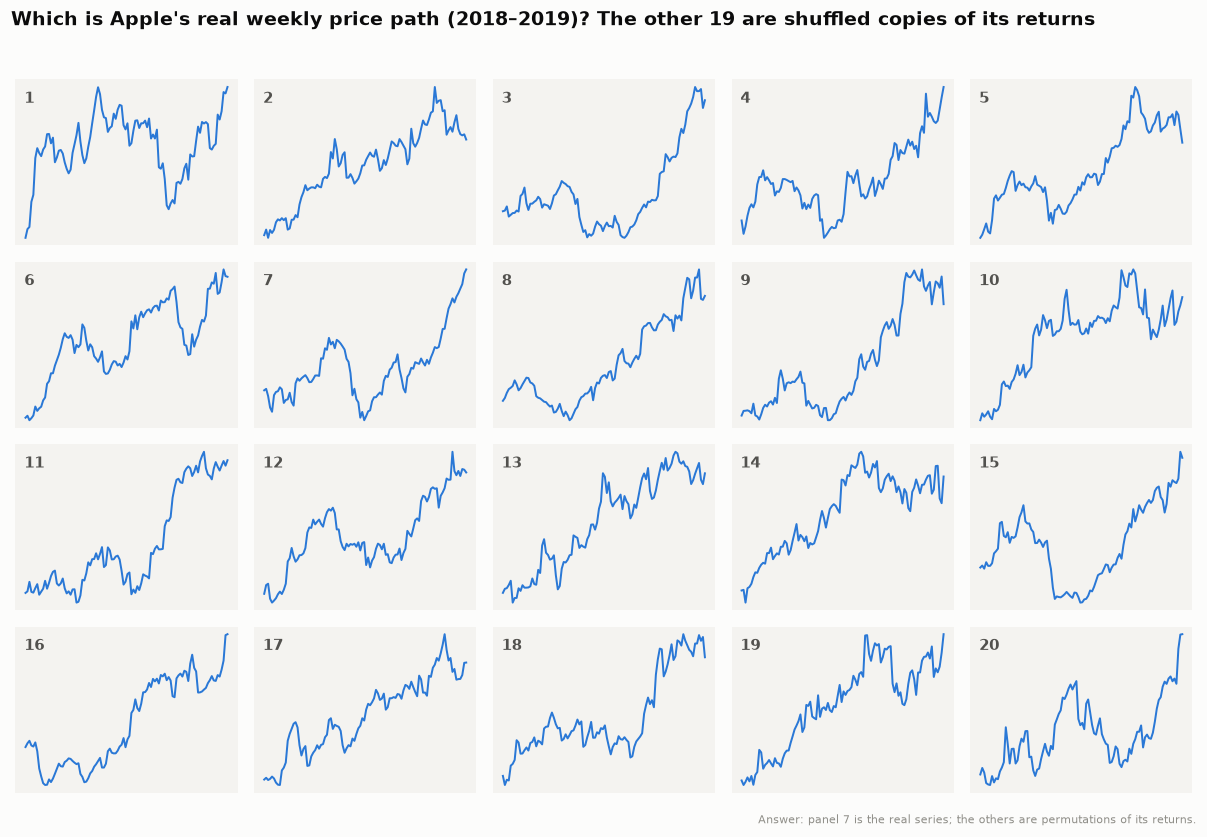

In [5]:
fig, axes = plt.subplots(4, 5, figsize=(11, 7.6))
for k, (ax, path) in enumerate(zip(axes.flat, panels), start=1):
    ax.plot(path, color=PALETTE[0], linewidth=1.3)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.set_facecolor("#f4f3f0")
    for s in ax.spines.values():
        s.set_visible(False)
    ax.text(0.04, 0.86, str(k), transform=ax.transAxes, fontsize=10, color="#52514e", fontweight="bold")
fig.suptitle(title, x=0.01, ha="left", fontweight="bold", fontsize=12.5)
fig.text(0.99, 0.008, f"Answer: panel {answer} is the real series; the others are permutations of its returns.",
         ha="right", fontsize=7.5, color="#8f8e88")
fig.tight_layout(rect=(0, 0.025, 1, 0.96))
plt.show()

---
Standalone script: [`lineup_protocol.py`](lineup_protocol.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)